# Music Sentiment as an Economic Signal

**Working research question:**  
Can shifts in popular music — especially sonic sentiment and genre composition — provide information that improves forecasts of future consumer sentiment?

### Current data architecture

This notebook uses two datasets:

1. **Ludmin Billboard Hot 100** — authoritative weekly chart backbone (`Date`, `Song`, `Artist`, `Rank`).
2. **550K Spotify Songs: Audio, Lyrics & Genres** — enrichment source for Spotify IDs, audio features, genre information, and later lyrics.

### Notebook philosophy

The main notebook now contains only the **production pipeline** needed to reproduce the current data preparation.

Exploratory diagnostics, rejected matching ideas, spot checks, and the reasoning that led to the final rules are summarized as commented notes in the **Appendix**. This keeps the workflow readable without erasing the audit trail.

Important decisions:

- Billboard `Date` controls time; the 550K `year` field is not authoritative.
- The 550K source is incomplete relative to the Hot 100, so coverage is measured explicitly.
- The final modeling window is **not frozen yet**; it should be chosen after rank-weighted monthly coverage is examined.


## 1. Imports and project paths

In [1]:
import ast
import re
import unicodedata
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

BILLBOARD_PATH = DATA_RAW / "hot100.csv"
SONGS_PATH = DATA_RAW / "songs.csv"

SONG_METADATA_PATH = (
    DATA_PROCESSED / "song_metadata.parquet"
)

ENGINEERED_METADATA_PATH = (
    DATA_PROCESSED / "song_metadata_engineered.parquet"
)

print("Project root:", PROJECT_ROOT)


Project root: /Users/mercyeme/Documents/Data_Projects_2026/RecessionPop


## 2. Load Billboard and lightweight 550K metadata

Billboard remains the weekly popularity/time table. Matching is performed once on unique `Song + Artist` pairs and then merged back to all weekly chart rows.

The 550K CSV is large because it contains lyrics, so the matching stage loads only metadata and audio-feature columns and caches them as Parquet.


In [2]:
billboard = pd.read_csv(BILLBOARD_PATH)
billboard["Date"] = pd.to_datetime(
    billboard["Date"]
)

billboard_songs = (
    billboard[["Song", "Artist"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Billboard weekly rows:", f"{len(billboard):,}")
print(
    "Unique Billboard song-artist pairs:",
    f"{len(billboard_songs):,}",
)
print(
    "Billboard range:",
    billboard["Date"].min(),
    "to",
    billboard["Date"].max(),
)


Billboard weekly rows: 354,858
Unique Billboard song-artist pairs: 32,592
Billboard range: 1958-07-30 00:00:00 to 2026-07-29 00:00:00


In [3]:
song_cols = [
    "id",
    "name",
    "album_name",
    "artists",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms",
    "year",
    "genre",
    "popularity",
    "total_artist_followers",
    "avg_artist_popularity",
    "artist_ids",
    "niche_genres",
]

if SONG_METADATA_PATH.exists():
    songs = pd.read_parquet(
        SONG_METADATA_PATH
    )
else:
    chunks = []

    for chunk in pd.read_csv(
        SONGS_PATH,
        usecols=song_cols,
        chunksize=50_000,
    ):
        chunks.append(chunk)

    songs = pd.concat(
        chunks,
        ignore_index=True,
    )

    songs.to_parquet(
        SONG_METADATA_PATH,
        index=False,
    )

print("550K metadata shape:", songs.shape)


550K metadata shape: (550622, 23)


## 3. Engineer genre and thematic features

The final genre logic is intentionally conservative:

- map the source's broad genre into the final taxonomy,
- allow only audited high-confidence niche tags to vote for an override,
- keep the broad source genre when niche evidence is absent or tied,
- retain religious content as a separate binary feature instead of treating it as a primary genre.

The long tag dictionary is kept in one cell because it is configuration, not a sequence of analytical steps.


In [4]:
def parse_genre_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []


songs["niche_genre_list"] = (
    songs["niche_genres"]
    .apply(parse_genre_list)
)

FINAL_GENRES = [
    "Pop",
    "Indie",
    "Rock",
    "Hip-Hop",
    "R&B/Soul",
    "Country",
    "Electronic/Dance",
    "Folk",
    "Reggae/Dancehall",
    "Latin/Tropical",
    "Afrobeats/African Pop",
    "Jazz",
    "Classical/Musical",
    "Blues",
    "Other",
]

BASE_GENRE_MAP = {
    "Pop": "Pop",
    "Rock": "Rock",
    "Hip-Hop": "Hip-Hop",
    "R&B": "R&B/Soul",
    "Country": "Country",
    "Electronic": "Electronic/Dance",
    "Folk": "Folk",
    "Jazz": "Jazz",
    "Classical": "Classical/Musical",
    "Blues": "Blues",
}

songs["genre_original"] = songs["genre"]

songs["genre_base"] = (
    songs["genre_original"]
    .map(BASE_GENRE_MAP)
    .fillna("Other")
)


In [5]:
GENRE_VOTE_TAGS = {

    "Reggae/Dancehall": {
        "calypso",
        "christian reggae",
        "dancehall",
        "dub",
        "lovers rock",
        "nz reggae",
        "ragga",
        "reggae",
        "reggae en español",
        "reggae pop",
        "reggae rock",
        "rocksteady",
        "roots reggae",
        "ska",
        "soca",
    },

    "Afrobeats/African Pop": {
        "afro adura",
        "afro r&b",
        "afro soul",
        "afrobeat",
        "afrobeats",
        "afrogospel",
        "afropiano",
        "afropop",
        "afroswing",
        "alté",
        "amapiano",
        "asakaa",
        "azonto",
        "bongo flava",
        "ghanaian hip hop",
        "highlife",
        "hiplife",
        "nigerian drill",
        "rumba congolaise",
    },

    "Latin/Tropical": {
        "bachata",
        "bolero",
        "bossa nova",
        "brazilian funk",
        "chilean mambo",
        "christian reggaeton",
        "corridos bélicos",
        "corridos tumbados",
        "cumbia",
        "cumbia norteña",
        "cumbia sonidera",
        "electro corridos",
        "electrocumbia",
        "forró",
        "forró tradicional",
        "funk carioca",
        "latin",
        "latin afrobeats",
        "latin alternative",
        "latin country",
        "latin dance",
        "latin folk",
        "latin folklore",
        "latin hip hop",
        "latin house",
        "latin indie",
        "latin jazz",
        "latin pop",
        "latin r&b",
        "latin rock",
        "mambo",
        "mariachi",
        "merengue",
        "mpb",
        "música mexicana",
        "new mpb",
        "norteño",
        "norteño-sax",
        "pagode",
        "pagode baiano",
        "ranchera",
        "reggaeton",
        "reggaeton chileno",
        "reggaeton mexa",
        "salsa",
        "samba",
        "sertanejo",
        "sertanejo tradicional",
        "sertanejo universitário",
        "tango",
        "trap latino",
        "urbano latino",
    },

    "Indie": {
        "indie",
        "chinese indie",
        "german indie",
        "hindi indie",
        "indian indie",
        "indie québécois",
        "indonesian indie",
        "japanese indie",
        "lo-fi indie",
        "mexican indie",
        "pinoy indie",
        "taiwanese indie",
        "tamil indie",
        "vietnam indie",
    },

    "R&B/Soul": {
        "alternative r&b",
        "classic soul",
        "dark r&b",
        "funk",
        "indie r&b",
        "indie soul",
        "motown",
        "neo soul",
        "new jack swing",
        "northern soul",
        "philly soul",
        "quiet storm",
        "r&b",
        "retro soul",
        "soul",
        "trap soul",
    },

    "Hip-Hop": {
        "alternative hip hop",
        "boom bap",
        "cloud rap",
        "crunk",
        "drill",
        "east coast hip hop",
        "emo rap",
        "experimental hip hop",
        "g-funk",
        "gangster rap",
        "hardcore hip hop",
        "hip hop",
        "melodic rap",
        "old school hip hop",
        "rap",
        "southern hip hop",
        "trap",
        "underground hip hop",
        "west coast hip hop",
    },

    "Electronic/Dance": {
        "deep house",
        "disco",
        "drum and bass",
        "dubstep",
        "ebm",
        "edm",
        "electro house",
        "electronic",
        "eurodance",
        "future bass",
        "hardstyle",
        "house",
        "melodic bass",
        "progressive house",
        "synthpop",
        "tech house",
        "techno",
        "trance",
        "tropical house",
    },

    "Country": {
        "alt country",
        "americana",
        "bluegrass",
        "classic country",
        "country",
        "honky tonk",
        "outlaw country",
        "red dirt",
        "texas country",
        "traditional country",
    },

    "Jazz": {
        "bebop",
        "big band",
        "cool jazz",
        "jazz",
        "jazz funk",
        "jazz fusion",
        "smooth jazz",
        "soul jazz",
        "swing music",
        "vocal jazz",
    },

    "Blues": {
        "blues",
        "classic blues",
        "country blues",
        "delta blues",
        "modern blues",
    },

    "Classical/Musical": {
        "baroque",
        "chamber music",
        "choral",
        "classical",
        "classical crossover",
        "contemporary classical",
        "musicals",
        "opera",
        "orchestral",
        "renaissance",
    },

    "Folk": {
        "anti-folk",
        "celtic folk",
        "folk",
        "folk pop",
        "indie folk",
        "singer-songwriter",
        "traditional folk",
    },

    "Rock": {
        "alternative rock",
        "art rock",
        "blues rock",
        "classic rock",
        "death metal",
        "funk rock",
        "garage rock",
        "glam rock",
        "grunge",
        "hard rock",
        "hardcore",
        "indie rock",
        "industrial metal",
        "industrial rock",
        "metal",
        "metalcore",
        "pop punk",
        "post-grunge",
        "post-hardcore",
        "power metal",
        "progressive rock",
        "psychedelic rock",
        "psychobilly",
        "punk",
        "rock",
        "rock and roll",
        "ska punk",
        "skate punk",
        "soft rock",
        "yacht rock",
    },

    "Pop": {
        "art pop",
        "baroque pop",
        "bedroom pop",
        "dance pop",
        "electropop",
        "funk pop",
        "indie pop",
        "j-pop",
        "k-pop",
        "pop",
        "power pop",
        "soft pop",
    },
}

# Additional explicit genre tags discovered during audit

GENRE_VOTE_TAGS["Rock"].update({
    "christian rock",
    "christian alternative rock",
    "southern rock",
    "celtic rock",
    "j-rock",
    "krautrock",
})

GENRE_VOTE_TAGS["Country"].update({
    "country christian",
    "christian bluegrass",
    "southern gospel",
})

GENRE_VOTE_TAGS["Folk"].update({
    "christian folk",
    "celtic",
})

GENRE_VOTE_TAGS["Pop"].update({
    "christian pop",
    "pop worship",
    "dream pop",
    "acoustic pop",
})

GENRE_VOTE_TAGS["R&B/Soul"].update({
    "christian r&b",
    "uk r&b",
})

GENRE_VOTE_TAGS["Hip-Hop"].update({
    "christian hip hop",
    "grime",
    "uk grime",
    "chinese hip hop",
    "k-rap",
    "miami bass",
})

GENRE_VOTE_TAGS["Electronic/Dance"].update({
    "alternative dance",
    "electro swing",
    "synthwave",
    "witch house",
})

GENRE_VOTE_TAGS["Jazz"].update({
    "acid jazz",
    "experimental jazz",
})

GENRE_VOTE_TAGS["Classical/Musical"].update({
    "gregorian chant",
})

# Additional religious subgenre votes that still preserve the separate
# religious_music flag.

GENRE_VOTE_TAGS["Jazz"].update({
    "christian jazz",
})

GENRE_VOTE_TAGS["R&B/Soul"].update({
    "funk gospel",
})

GENRE_VOTE_TAGS["Latin/Tropical"].update({
    "brazilian gospel",
    "pagode gospel",
    "sertanejo gospel",
})

# Tags that are meaningful but too cross-genre to force a primary classification.

INHERIT_TAGS = {
    "industrial",
    "darkwave",
    "new wave",
    "riddim",
    "folk rock",
    "country rock",
    "gospel",
    "traditional gospel",
}

# Descriptors/context tags that should not vote for a primary musical genre.

PRIMARY_GENRE_IGNORE_TAGS = {
    "christian",
    "christmas",
    "worship",
    "ccm",
    "hymns",
    "soundtrack",
    "children's music",
    "comedy",
}

In [6]:
RELIGIOUS_TAGS = {
    "christian",
    "christian alternative rock",
    "christian bluegrass",
    "christian folk",
    "christian hip hop",
    "christian jazz",
    "christian lo-fi",
    "christian pop",
    "christian r&b",
    "christian reggae",
    "christian reggaeton",
    "christian rock",
    "country christian",
    "ccm",
    "gospel",
    "traditional gospel",
    "southern gospel",
    "afrogospel",
    "brazilian gospel",
    "funk gospel",
    "pagode gospel",
    "sertanejo gospel",
    "worship",
    "pop worship",
    "hymns",
    "catholic music",
}


def genre_scores(tags):
    tag_set = {
        str(tag).lower().strip()
        for tag in tags
        if pd.notna(tag)
    }

    return {
        category: len(
            tag_set & category_tags
        )
        for category, category_tags
        in GENRE_VOTE_TAGS.items()
    }


def choose_genre_override(tags):
    scores = genre_scores(tags)
    best_score = max(scores.values())

    if best_score == 0:
        return None

    winners = [
        category
        for category, score in scores.items()
        if score == best_score
    ]

    return (
        winners[0]
        if len(winners) == 1
        else None
    )


def has_religious_tag(tags):
    tag_set = {
        str(tag).lower().strip()
        for tag in tags
        if pd.notna(tag)
    }

    return int(
        bool(tag_set & RELIGIOUS_TAGS)
    )


# Sanity-check the rule configuration.
tag_to_categories = {}

for category, tags in GENRE_VOTE_TAGS.items():
    for tag in tags:
        tag_to_categories.setdefault(
            tag,
            [],
        ).append(category)

duplicate_vote_tags = {
    tag: categories
    for tag, categories
    in tag_to_categories.items()
    if len(categories) > 1
}

assert not duplicate_vote_tags

vote_tags = set().union(
    *GENRE_VOTE_TAGS.values()
)

assert not (
    vote_tags & INHERIT_TAGS
)
assert not (
    vote_tags
    & PRIMARY_GENRE_IGNORE_TAGS
)
assert not (
    INHERIT_TAGS
    & PRIMARY_GENRE_IGNORE_TAGS
)

# Apply the final rules.
songs["genre_override"] = (
    songs["niche_genre_list"]
    .apply(choose_genre_override)
)

songs["genre_engineered"] = (
    songs["genre_override"]
    .fillna(songs["genre_base"])
)

songs["religious_music"] = (
    songs["niche_genre_list"]
    .apply(has_religious_tag)
)

unexpected_genres = (
    set(
        songs[
            "genre_engineered"
        ].dropna().unique()
    )
    - set(FINAL_GENRES)
)

assert not unexpected_genres

print(
    "High-confidence voting tags:",
    len(tag_to_categories),
)
print(
    "Religiously tagged songs:",
    f"{songs['religious_music'].sum():,}",
)

display(
    songs["genre_engineered"]
    .value_counts()
    .rename("song_count")
)


High-confidence voting tags: 273
Religiously tagged songs: 30,324


genre_engineered
Rock                     207008
Electronic/Dance          67840
Pop                       58224
Country                   46178
Hip-Hop                   40467
R&B/Soul                  32787
Folk                      31818
Jazz                      17846
Reggae/Dancehall          15770
Blues                     11923
Classical/Musical         10688
Indie                      3777
Afrobeats/African Pop      3740
Latin/Tropical             2556
Name: song_count, dtype: int64

In [7]:
songs.to_parquet(
    ENGINEERED_METADATA_PATH,
    index=False,
)

print(
    "Saved engineered metadata:",
    ENGINEERED_METADATA_PATH,
)


Saved engineered metadata: /Users/mercyeme/Documents/Data_Projects_2026/RecessionPop/data/processed/song_metadata_engineered.parquet


## 4. Build a canonical 550K song lookup

Matching uses normalized title and artist keys while retaining all original text.

Because the 550K source often repeats the same recording across albums, compilations, and reissues, each normalized `title + primary artist` key is reduced to one canonical row:

1. prefer the most common rounded audio signature,
2. then the highest Spotify popularity within that signature,
3. then Spotify ID as a stable tie-breaker.

The rounded signature is used only for duplicate resolution; the original audio features remain unchanged.


In [8]:
def normalize_text(value):
    if pd.isna(value):
        return ""

    value = str(value).lower().strip()

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        char
        for char in value
        if not unicodedata.combining(char)
    )

    value = value.replace(
        "&",
        "and",
    )

    value = re.sub(
        r"[^\w\s]",
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return value.strip()


def parse_artist_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(value)
        return (
            parsed
            if isinstance(parsed, list)
            else []
        )
    except (
        ValueError,
        SyntaxError,
        TypeError,
    ):
        return []


billboard_songs["title_key"] = (
    billboard_songs["Song"]
    .map(normalize_text)
)

billboard_songs["artist_key"] = (
    billboard_songs["Artist"]
    .map(normalize_text)
)

songs["artist_list"] = (
    songs["artists"]
    .apply(parse_artist_list)
)

songs["primary_artist"] = (
    songs["artist_list"]
    .str[0]
)

songs["title_key"] = (
    songs["name"]
    .map(normalize_text)
)

songs["artist_key"] = (
    songs["primary_artist"]
    .map(normalize_text)
)


In [9]:
match_cols = [
    "id",
    "name",
    "album_name",
    "artists",
    "primary_artist",
    "title_key",
    "artist_key",
    "year",
    "popularity",
    "valence",
    "energy",
    "danceability",
    "tempo",
    "mode",
    "duration_ms",
    "genre_original",
    "genre_engineered",
    "religious_music",
]

spotify_lookup = (
    songs[match_cols]
    .loc[
        lambda df:
        df["title_key"].ne("")
        & df["artist_key"].ne("")
    ]
    .copy()
)

spotify_lookup["sig_danceability"] = (
    spotify_lookup["danceability"]
    .round(3)
)
spotify_lookup["sig_energy"] = (
    spotify_lookup["energy"]
    .round(3)
)
spotify_lookup["sig_valence"] = (
    spotify_lookup["valence"]
    .round(3)
)
spotify_lookup["sig_tempo"] = (
    spotify_lookup["tempo"]
    .round(1)
)
spotify_lookup["sig_duration"] = (
    spotify_lookup["duration_ms"]
    .div(1000)
    .round()
)

signature_cols = [
    "sig_danceability",
    "sig_energy",
    "sig_valence",
    "sig_tempo",
    "sig_duration",
]

spotify_lookup["candidate_count"] = (
    spotify_lookup
    .groupby(
        [
            "title_key",
            "artist_key",
        ],
        dropna=False,
    )["id"]
    .transform("size")
)

spotify_lookup["signature_count"] = (
    spotify_lookup
    .groupby(
        [
            "title_key",
            "artist_key",
        ]
        + signature_cols,
        dropna=False,
    )["id"]
    .transform("size")
)

spotify_lookup["signature_share"] = (
    spotify_lookup["signature_count"]
    / spotify_lookup["candidate_count"]
)

spotify_lookup["popularity_sort"] = (
    spotify_lookup["popularity"]
    .fillna(-1)
)

spotify_exact_canonical = (
    spotify_lookup
    .sort_values(
        [
            "title_key",
            "artist_key",
            "signature_count",
            "popularity_sort",
            "id",
        ],
        ascending=[
            True,
            True,
            False,
            False,
            True,
        ],
    )
    .drop_duplicates(
        subset=[
            "title_key",
            "artist_key",
        ],
        keep="first",
    )
    .drop(
        columns="popularity_sort"
    )
    .reset_index(drop=True)
)

assert not (
    spotify_exact_canonical
    .duplicated(
        [
            "title_key",
            "artist_key",
        ]
    )
    .any()
)

print(
    "Canonical 550K title-artist rows:",
    f"{len(spotify_exact_canonical):,}",
)


Canonical 550K title-artist rows: 469,176


## 5. Match Billboard songs to the canonical 550K lookup

The production matcher uses three conservative passes:

- **Pass 1:** exact normalized title + exact normalized artist.
- **Pass 2:** exact title + Billboard lead artist after removing an explicit `Featuring ...` suffix.
- **Pass 3:** Spotify embeds a feature credit in the title; remove only that feature-credit phrase, preserve version/remix text, require the same lead artist, and require collaborator overlap.

Fourteen Pass-3 Billboard songs had two surviving Spotify candidates. Twelve were resolved after manual audit; two genuine `Or`-credit cases were deliberately left unresolved. The audit trail is documented in the Appendix.


In [10]:
# ---------- Pass 1: exact title + artist ----------

exact_matches = (
    billboard_songs
    .merge(
        spotify_exact_canonical,
        on=[
            "title_key",
            "artist_key",
        ],
        how="left",
        indicator="_merge_exact",
        validate="many_to_one",
    )
)

exact_match_map = (
    exact_matches.loc[
        exact_matches[
            "_merge_exact"
        ] == "both",
        [
            "Song",
            "Artist",
            "id",
        ],
    ]
    .rename(
        columns={
            "id": "spotify_id",
        }
    )
    .copy()
)

exact_match_map["match_method"] = (
    "exact_title_artist"
)


# ---------- Pass 2: Billboard Featuring credit ----------

def remove_featuring(artist_key):
    return re.sub(
        r"\s+featuring\s+.*$",
        "",
        artist_key,
    ).strip()


remaining_after_pass1 = (
    exact_matches.loc[
        exact_matches[
            "_merge_exact"
        ] == "left_only",
        [
            "Song",
            "Artist",
            "title_key",
            "artist_key",
        ],
    ]
    .copy()
)

remaining_after_pass1[
    "billboard_lead_artist_key"
] = (
    remaining_after_pass1[
        "artist_key"
    ]
    .map(remove_featuring)
)

remaining_after_pass1[
    "has_featuring_credit"
] = (
    remaining_after_pass1[
        "artist_key"
    ]
    .str.contains(
        r"\bfeaturing\b",
        regex=True,
        na=False,
    )
)

featuring_candidates = (
    remaining_after_pass1.loc[
        remaining_after_pass1[
            "has_featuring_credit"
        ]
    ]
    .merge(
        spotify_exact_canonical,
        left_on=[
            "title_key",
            "billboard_lead_artist_key",
        ],
        right_on=[
            "title_key",
            "artist_key",
        ],
        how="left",
        validate="many_to_one",
        suffixes=(
            "_billboard",
            "_spotify",
        ),
    )
)

featuring_match_map = (
    featuring_candidates.loc[
        featuring_candidates[
            "id"
        ].notna(),
        [
            "Song",
            "Artist",
            "id",
        ],
    ]
    .rename(
        columns={
            "id": "spotify_id",
        }
    )
    .copy()
)

featuring_match_map[
    "match_method"
] = (
    "exact_title_lead_artist_after_featuring"
)


In [11]:
# ---------- Pass 3: feature credit embedded in Spotify title ----------

def remove_spotify_title_feature_credit(title):
    if pd.isna(title):
        return ""

    title = str(title)

    # Remove a parenthetical feature credit,
    # but preserve any text that follows it.
    title = re.sub(
        r"\s*[\(\[]\s*(?:feat\.?|featuring)\s+[^\)\]]+[\)\]]",
        "",
        title,
        flags=re.IGNORECASE,
    )

    # Remove a terminal feature credit only
    # when it actually ends the title.
    title = re.sub(
        r"\s+(?:feat\.?|featuring)\s+[^-]+$",
        "",
        title,
        flags=re.IGNORECASE,
    )

    return title.strip()


spotify_exact_canonical[
    "title_no_feature_key"
] = (
    spotify_exact_canonical["name"]
    .map(
        remove_spotify_title_feature_credit
    )
    .map(normalize_text)
)

pass12_map = pd.concat(
    [
        exact_match_map,
        featuring_match_map,
    ],
    ignore_index=True,
)

remaining_after_pass2 = (
    billboard_songs
    .merge(
        pass12_map[
            [
                "Song",
                "Artist",
                "spotify_id",
            ]
        ],
        on=[
            "Song",
            "Artist",
        ],
        how="left",
        validate="one_to_one",
    )
    .loc[
        lambda df:
        df["spotify_id"].isna(),
        [
            "Song",
            "Artist",
            "title_key",
            "artist_key",
        ],
    ]
    .copy()
)

remaining_after_pass2[
    "billboard_lead_artist_key"
] = (
    remaining_after_pass2[
        "artist_key"
    ]
    .map(remove_featuring)
)

title_feature_candidates = (
    remaining_after_pass2
    .merge(
        spotify_exact_canonical,
        left_on=[
            "title_key",
            "billboard_lead_artist_key",
        ],
        right_on=[
            "title_no_feature_key",
            "artist_key",
        ],
        how="inner",
        suffixes=(
            "_billboard",
            "_spotify",
        ),
    )
)

title_feature_candidates[
    "spotify_artist_keys"
] = (
    title_feature_candidates[
        "artists"
    ]
    .apply(parse_artist_list)
    .apply(
        lambda artists: [
            normalize_text(artist)
            for artist in artists
        ]
    )
)

title_feature_candidates[
    "spotify_secondary_keys"
] = (
    title_feature_candidates[
        "spotify_artist_keys"
    ]
    .apply(
        lambda artists:
        artists[1:]
    )
)

title_feature_candidates[
    "billboard_has_featuring"
] = (
    title_feature_candidates[
        "artist_key_billboard"
    ]
    .str.contains(
        r"\bfeaturing\b",
        regex=True,
        na=False,
    )
)


def has_secondary_artist_overlap(row):
    return any(
        artist
        and artist
        in row[
            "artist_key_billboard"
        ]
        for artist
        in row[
            "spotify_secondary_keys"
        ]
    )


title_feature_candidates[
    "secondary_artist_overlap"
] = (
    title_feature_candidates
    .apply(
        has_secondary_artist_overlap,
        axis=1,
    )
)

strong_pass3_candidates = (
    title_feature_candidates.loc[
        title_feature_candidates[
            "billboard_has_featuring"
        ]
        & title_feature_candidates[
            "secondary_artist_overlap"
        ]
    ]
    .copy()
)

strong_pass3_candidates[
    "candidate_rows"
] = (
    strong_pass3_candidates
    .groupby(
        [
            "Song",
            "Artist",
        ]
    )["id"]
    .transform("size")
)

pass3_unique_match_map = (
    strong_pass3_candidates.loc[
        strong_pass3_candidates[
            "candidate_rows"
        ] == 1,
        [
            "Song",
            "Artist",
            "id",
        ],
    ]
    .rename(
        columns={
            "id": "spotify_id",
        }
    )
    .copy()
)

pass3_unique_match_map[
    "match_method"
] = (
    "exact_title_after_feature_strip_"
    "lead_artist_secondary_overlap"
)


In [12]:
# ---------- Audited Pass-3 ambiguous resolutions ----------

# Twelve of the fourteen two-candidate cases were
# manually resolvable from collaborator credits /
# duplicate-recording metadata. Two "Or" cases
# remain intentionally unmatched.
PASS3_MANUAL_IDS = {
    "53Y0kdCa1CZ9gRqEuknfwy",  # Bang My Head
    "6yuvC80FcnVJNvC0DbXN9e",  # Come To Me
    "1MZtr7IH5qtjIkqrXj8WOJ",  # Essence
    "2npw9XuCQpHXM9ramYL4HR",  # Ima Boss
    "50DMJJpAeQv4fIpxZvQz2e",  # Monsters
    "31dgrKXIJ7FCxlENs8uxuo",  # Show Me Love
    "2eSJflipjhSKLExuSwuFrO",  # What's Luv?
    "1fLibtVj3MrNTwRZq5yUOs",  # Let's Go
    "7kQJCw0ZkvHgfJqRwPblmG",  # Neck & Wrist
    "5qqBsCBwzv0g0xb1kB1TGJ",  # Off The Books
    "66MsAs4nVj68t6va1lygIm",  # Shut Up
    "7x9nXsowok1JszkVztI5NI",  # Writing On The Wall
}

pass3_manual_match_map = (
    strong_pass3_candidates.loc[
        strong_pass3_candidates[
            "id"
        ].isin(PASS3_MANUAL_IDS),
        [
            "Song",
            "Artist",
            "id",
        ],
    ]
    .rename(
        columns={
            "id": "spotify_id",
        }
    )
    .drop_duplicates()
    .reset_index(drop=True)
)

pass3_manual_match_map[
    "match_method"
] = (
    "manual_ambiguous_feature_credit_review"
)

assert (
    len(pass3_manual_match_map)
    == 12
)

pass3_match_map = pd.concat(
    [
        pass3_unique_match_map,
        pass3_manual_match_map,
    ],
    ignore_index=True,
)

billboard_song_match_map = pd.concat(
    [
        exact_match_map,
        featuring_match_map,
        pass3_match_map,
    ],
    ignore_index=True,
)

assert not (
    billboard_song_match_map
    .duplicated(
        [
            "Song",
            "Artist",
        ]
    )
    .any()
)

billboard_song_matches = (
    billboard_songs
    .merge(
        billboard_song_match_map,
        on=[
            "Song",
            "Artist",
        ],
        how="left",
        validate="one_to_one",
    )
)

print(
    billboard_song_matches[
        "match_method"
    ].value_counts(dropna=False)
)

print(
    "\nMatched unique songs:",
    f"{billboard_song_matches['spotify_id'].notna().sum():,}",
)

print(
    "Unique-song coverage:",
    f"{billboard_song_matches['spotify_id'].notna().mean():.1%}",
)


match_method
NaN                                                              20616
exact_title_artist                                               10466
exact_title_lead_artist_after_featuring                            798
exact_title_after_feature_strip_lead_artist_secondary_overlap      700
manual_ambiguous_feature_credit_review                              12
Name: count, dtype: int64

Matched unique songs: 11,976
Unique-song coverage: 36.7%


## 6. Measure 550K coverage on the actual Billboard chart

Unique-song coverage is useful for linkage auditing, but the forecasting signal is based on chart observations.

Coverage is therefore measured again on weekly Billboard rows and with a rank weight of `101 - Rank`. The monthly rank-weighted series is the important quality-control metric for deciding the usable modeling window.


In [13]:
billboard_weekly_550k_matches = (
    billboard
    .merge(
        billboard_song_matches[
            [
                "Song",
                "Artist",
                "spotify_id",
                "match_method",
            ]
        ],
        on=[
            "Song",
            "Artist",
        ],
        how="left",
        validate="many_to_one",
    )
)

billboard_weekly_550k_matches[
    "year"
] = (
    billboard_weekly_550k_matches[
        "Date"
    ].dt.year
)

billboard_weekly_550k_matches[
    "raw_weight"
] = (
    101
    - billboard_weekly_550k_matches[
        "Rank"
    ]
)

billboard_weekly_550k_matches[
    "matched_weight"
] = (
    billboard_weekly_550k_matches[
        "raw_weight"
    ]
    * billboard_weekly_550k_matches[
        "spotify_id"
    ].notna()
)

yearly_coverage = (
    billboard_weekly_550k_matches
    .groupby("year")
    .agg(
        weekly_rows=(
            "Song",
            "size",
        ),
        matched_weekly_rows=(
            "spotify_id",
            lambda x:
            x.notna().sum(),
        ),
        total_rank_weight=(
            "raw_weight",
            "sum",
        ),
        matched_rank_weight=(
            "matched_weight",
            "sum",
        ),
    )
)

yearly_coverage[
    "weekly_match_rate"
] = (
    yearly_coverage[
        "matched_weekly_rows"
    ]
    / yearly_coverage[
        "weekly_rows"
    ]
)

yearly_coverage[
    "rank_weighted_match_rate"
] = (
    yearly_coverage[
        "matched_rank_weight"
    ]
    / yearly_coverage[
        "total_rank_weight"
    ]
)

display(
    yearly_coverage.tail(40)
)


,weekly_rows,matched_weekly_rows,total_rank_weight,matched_rank_weight,weekly_match_rate,rank_weighted_match_rate
year,,,,,,
1987,5200,2319,262600,121806,0.445962,0.463846
1988,5200,2414,262600,121440,0.464231,0.462452
1989,5199,2258,262598,114613,0.434314,0.436458
1990,5200,2381,262600,128224,0.457885,0.488286
1991,5200,2247,262600,124244,0.432115,0.473130
1992,5300,2334,267650,121882,0.440377,0.455378
1993,5200,2352,262600,128327,0.452308,0.488679
1994,5200,2606,262600,136212,0.501154,0.518705
1995,5200,2384,262600,116480,0.458462,0.443564


In [14]:
billboard_weekly_550k_matches[
    "month"
] = (
    billboard_weekly_550k_matches[
        "Date"
    ]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_rank_weighted_coverage = (
    billboard_weekly_550k_matches
    .groupby("month")
    .agg(
        total_rank_weight=(
            "raw_weight",
            "sum",
        ),
        matched_rank_weight=(
            "matched_weight",
            "sum",
        ),
    )
)

monthly_rank_weighted_coverage[
    "rank_weighted_match_rate"
] = (
    monthly_rank_weighted_coverage[
        "matched_rank_weight"
    ]
    / monthly_rank_weighted_coverage[
        "total_rank_weight"
    ]
)

display(
    monthly_rank_weighted_coverage.tail(36)
)


,total_rank_weight,matched_rank_weight,rank_weighted_match_rate
month,,,
2023-08-01,25250,2963,0.117347
2023-09-01,20200,1604,0.079406
2023-10-01,20200,1083,0.053614
2023-11-01,25250,2155,0.085347
2023-12-01,20200,6705,0.331931
2024-01-01,25250,2839,0.112436
2024-02-01,20200,678,0.033564
2024-03-01,20200,873,0.043218
2024-04-01,20200,808,0.040000


## Current stopping point

The production notebook now does four things:

1. loads Ludmin + lightweight 550K metadata,
2. engineers the final genre / religious features,
3. builds the audited deterministic Billboard-to-550K match map,
4. measures raw and rank-weighted coverage.

**Next:** inspect monthly rank-weighted coverage before choosing the analysis window. After that, attach the canonical Spotify audio features back to the weekly Billboard rows and construct monthly music features.


In [15]:
matched_spotify_ids = set(
    billboard_song_match_map[
        "spotify_id"
    ].dropna()
)

lyrics_chunks = []

for chunk in pd.read_csv(
    SONGS_PATH,
    usecols=["id", "lyrics"],
    chunksize=50_000,
):
    matched_chunk = chunk.loc[
        chunk["id"].isin(
            matched_spotify_ids
        )
    ].copy()

    if not matched_chunk.empty:
        lyrics_chunks.append(
            matched_chunk
        )

matched_lyrics = (
    pd.concat(
        lyrics_chunks,
        ignore_index=True,
    )
    .drop_duplicates(
        subset="id"
    )
)

print(
    "Matched Spotify IDs:",
    f"{len(matched_spotify_ids):,}",
)

print(
    "IDs found in lyrics file:",
    f"{len(matched_lyrics):,}",
)

print(
    "Non-missing lyrics:",
    f"{matched_lyrics['lyrics'].notna().sum():,}",
)

display(
    matched_lyrics.head()
)

Matched Spotify IDs: 11,974
IDs found in lyrics file: 11,974
Non-missing lyrics: 11,974


,id,lyrics
0,7rSj5gEdN5KgHwbnEVAZ4b,"Uh, uh, uh\nI just gotta bring it to they atte..."
1,1ahAuX3F6tDdNRfMdiLsv6,"Ah, ah, you're beautiful\nAh, ah, you're beaut..."
2,1HOlb9rdNOmy9b1Fakicjo,When Jason was at the table\nI kept on seeing ...
3,01TuObJVd7owWchVRuQbQw,"And oh, I'm alive, I'm alive, I'm alive\nAnd o..."
4,1TkWsnheqK0gBtvh07BtNX,"LD, AKA The Independent Variable\nTrap God, an..."


In [16]:
matched_lyrics["char_count"] = (
    matched_lyrics["lyrics"]
    .str.len()
)

matched_lyrics["word_count"] = (
    matched_lyrics["lyrics"]
    .str.split()
    .str.len()
)

print(
    matched_lyrics[
        ["char_count", "word_count"]
    ].describe()
)

display(
    matched_lyrics
    .nsmallest(
        20,
        "word_count",
    )[
        [
            "id",
            "word_count",
            "lyrics",
        ]
    ]
)

         char_count    word_count
count  11974.000000  11974.000000
mean    1704.672624    340.849173
std      945.947851    187.389010
min       31.000000      6.000000
25%     1062.250000    214.000000
50%     1443.000000    290.000000
75%     2063.000000    414.750000
max    10474.000000   1976.000000


,id,word_count,lyrics
3122,5i7fZq3chLyCHo3VeB6goD,6,(Call 911 now!)\n(Call 911 now!)
773,1TWfkGrhF7ob0nwB2M6knb,8,We're the fuckin' animals\nWe're the fuckin' a...
10056,2irlk8IK9WNdxQrqHa9Wll,16,"Popcorn, hey\nPopcorn, hey\nPopcorn, hey\nPopc..."
5426,7sBgFMWqDWQgrsNSpIBoe8,26,Every knee shall bow\nEvery tongue confess\nJe...
6200,5x9239aGsatbpoPHSbDXBv,27,'Cause Downtown Brooklyn Is Where I Was Born =...
8476,4rwpZEcnalkuhPyGkEdhu0,27,"Yes, oh my god\nYes, oh my god\nLook at this, ..."
10897,4aHcGoFLj0Jg5bc3g62KhU,35,(John Stocklin)\n\nWant you to know you made m...
9954,06sImcalauWP5m1XIWTLTI,41,Do it!\nDo it!\nDo it!\n\nDo the Hustle!\nDo t...
11086,3xuobJ0EyP0Boajt7p8xWq,44,Yeah. Flipmode. Violator.\nNeptunes nigga\nWha...
3794,6p7KEJStN2J1EpsT3hZVqH,45,People fighting for a dollar.\nThe proof in th...


In [23]:
matched_lyrics["lyric_valid"] = (
    matched_lyrics["word_count"] >= 20
)

print(
    matched_lyrics["lyric_valid"]
    .value_counts()
)

print(
    "Valid lyric rate:",
    f"{matched_lyrics['lyric_valid'].mean():.2%}",
)

lyric_valid
True     11971
False        3
Name: count, dtype: int64
Valid lyric rate: 99.97%


In [24]:
from zipfile import ZipFile

NRC_PATH = (
    DATA_RAW / "NRC-Emotion-Lexicon.zip"
)

NRC_MEMBER = (
    "NRC-Emotion-Lexicon/"
    "NRC-Emotion-Lexicon-Wordlevel-v0.92.txt"
)

with ZipFile(NRC_PATH) as z:
    with z.open(NRC_MEMBER) as f:
        nrc_long = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=[
                "word",
                "emotion",
                "association",
            ],
        )

print(nrc_long.shape)
display(nrc_long.head(20))

(141540, 3)


,word,emotion,association
0,aback,anger,0
1,aback,anticipation,0
2,aback,disgust,0
3,aback,fear,0
4,aback,joy,0
5,aback,negative,0
6,aback,positive,0
7,aback,sadness,0
8,aback,surprise,0
9,aback,trust,0


In [25]:
nrc = (
    nrc_long
    .pivot(
        index="word",
        columns="emotion",
        values="association",
    )
    .reset_index()
)

print(nrc.shape)

display(
    nrc.head(10)
)

(14154, 11)


emotion,word,anger,anticipation,disgust,fear,joy,negative,positive,sadness,surprise,trust
0,NaN,0,0,0,0,0,0,0,0,0,0
1,aback,0,0,0,0,0,0,0,0,0,0
2,abacus,0,0,0,0,0,0,0,0,0,1
3,abandon,0,0,0,1,0,1,0,1,0,0
4,abandoned,1,0,0,1,0,1,0,1,0,0
5,abandonment,1,0,0,1,0,1,0,1,1,0
6,abate,0,0,0,0,0,0,0,0,0,0
7,abatement,0,0,0,0,0,0,0,0,0,0
8,abba,0,0,0,0,0,0,1,0,0,0
9,abbot,0,0,0,0,0,0,0,0,0,1


In [26]:
nrc = (
    nrc
    .dropna(subset=["word"])
    .reset_index(drop=True)
)

print(nrc.shape)
display(nrc.head())

(14153, 11)


emotion,word,anger,anticipation,disgust,fear,joy,negative,positive,sadness,surprise,trust
0,aback,0,0,0,0,0,0,0,0,0,0
1,abacus,0,0,0,0,0,0,0,0,0,1
2,abandon,0,0,0,1,0,1,0,1,0,0
3,abandoned,1,0,0,1,0,1,0,1,0,0
4,abandonment,1,0,0,1,0,1,0,1,1,0


In [27]:
import re
from collections import Counter

emotion_cols = [
    "anger",
    "anticipation",
    "disgust",
    "fear",
    "joy",
    "negative",
    "positive",
    "sadness",
    "surprise",
    "trust",
]

nrc_lookup = (
    nrc
    .set_index("word")[emotion_cols]
    .to_dict(orient="index")
)


def score_lyrics_nrc(text, valid=True):
    if not valid:
        return pd.Series(
            {
                "nrc_token_count": 0,
                "nrc_matched_tokens": 0,
                "nrc_coverage": float("nan"),
                **{
                    f"{emotion}_rate": float("nan")
                    for emotion in emotion_cols
                },
            }
        )

    tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?",
        str(text).lower(),
    )

    token_counts = Counter(tokens)

    emotion_counts = {
        emotion: 0
        for emotion in emotion_cols
    }

    matched_tokens = 0

    for word, count in token_counts.items():
        if word not in nrc_lookup:
            continue

        matched_tokens += count

        for emotion in emotion_cols:
            emotion_counts[emotion] += (
                nrc_lookup[word][emotion]
                * count
            )

    total_tokens = len(tokens)

    result = {
        "nrc_token_count": total_tokens,
        "nrc_matched_tokens": matched_tokens,
        "nrc_coverage": (
            matched_tokens / total_tokens
            if total_tokens > 0
            else float("nan")
        ),
    }

    for emotion in emotion_cols:
        result[f"{emotion}_rate"] = (
            emotion_counts[emotion]
            / total_tokens
            if total_tokens > 0
            else float("nan")
        )

    return pd.Series(result)

In [28]:
nrc_scores = matched_lyrics.apply(
    lambda row: score_lyrics_nrc(
        row["lyrics"],
        row["lyric_valid"],
    ),
    axis=1,
)

matched_lyrics = pd.concat(
    [
        matched_lyrics,
        nrc_scores,
    ],
    axis=1,
)

In [29]:
print(
    matched_lyrics["nrc_coverage"]
    .describe()
)

display(
    matched_lyrics[
        [
            "id",
            "word_count",
            "nrc_coverage",
            "positive_rate",
            "negative_rate",
            "joy_rate",
            "sadness_rate",
        ]
    ].head(10)
)

count    11971.000000
mean         0.209459
std          0.062417
min          0.000000
25%          0.168464
50%          0.205263
75%          0.244898
max          0.781250
Name: nrc_coverage, dtype: float64


,id,word_count,nrc_coverage,positive_rate,negative_rate,joy_rate,sadness_rate
0,7rSj5gEdN5KgHwbnEVAZ4b,705,0.188732,0.033803,0.032394,0.008451,0.014085
1,1ahAuX3F6tDdNRfMdiLsv6,259,0.253846,0.115385,0.042308,0.103846,0.011538
2,1HOlb9rdNOmy9b1Fakicjo,327,0.120000,0.021538,0.021538,0.012308,0.003077
3,01TuObJVd7owWchVRuQbQw,393,0.211443,0.054726,0.012438,0.049751,0.004975
4,1TkWsnheqK0gBtvh07BtNX,1057,0.251887,0.115094,0.028302,0.067925,0.010377
5,4XCvXkbtuPLs4bjDPpJvQW,225,0.233480,0.052863,0.017621,0.044053,0.008811
6,0aJHZYjwbfTmeyUWF7zGxI,200,0.145000,0.030000,0.035000,0.020000,0.020000
7,2R97RZWUx4vAFbMMtmb5Ss,480,0.205285,0.089431,0.032520,0.081301,0.014228
8,1CKmI1IQjVEVB3F7VmJmM3,272,0.213235,0.025735,0.011029,0.007353,0.007353
9,79kSICGWZBR9LPf70HqN6N,255,0.141176,0.062745,0.035294,0.058824,0.031373


In [30]:
print(
    "Zero NRC matches:",
    (matched_lyrics["nrc_matched_tokens"] == 0).sum()
)

print(
    "Under 5% NRC coverage:",
    (matched_lyrics["nrc_coverage"] < 0.05).sum()
)

display(
    matched_lyrics.loc[
        matched_lyrics["nrc_coverage"] < 0.05,
        [
            "id",
            "word_count",
            "nrc_matched_tokens",
            "nrc_coverage",
            "lyrics",
        ],
    ].head(20)
)

Zero NRC matches: 7
Under 5% NRC coverage: 24


,id,word_count,nrc_matched_tokens,nrc_coverage,lyrics
12,2erTdgDOZmjJNaNhjhWXhJ,191,8.0,0.040609,Never felt like this until I kissed ya\nHow di...
467,0qgYfRBF5mSCPOdHdgus66,239,12.0,0.049180,Ain't no way for me to love you\nIf you won't ...
1069,2gjvVycn75APfdTD3rgRww,243,0.0,0.000000,Barbra Streisand\nOoh ooh ooh ooh ooh ooh ooh\...
1896,7rr8ZP1Ezup3DKpqLY20bl,106,0.0,0.000000,Dengarkanlah suara hati ini\nSuara hati yang i...
2141,0fonScmHUzC0MglSLn9saA,231,12.0,0.033803,I met him on a Monday and my heart stood still...
2398,1qBrdgxB15xuDYLeKKu1J6,404,9.0,0.021429,Are you strong enough?\nGive me what I wants\n...
3451,66wkmlfx3H0Oqg1frvJjhu,112,0.0,0.000000,That's right!\nGet up and boogie\nGet up and b...
4981,5A0aUvnfAEcmUx3hoXjI8R,471,22.0,0.046709,Boy there you go\nYou're tellin me that you lo...
5424,0bux8uey9F2gKAY3OMCUFW,194,6.0,0.030928,Jesus is just all right with me\nJesus is just...
6556,1SN5fcUZyWFktGbEoHdHOm,284,14.0,0.049123,Mama said there'll be days like this\nThere'll...


In [31]:
emotion_rate_cols = [
    f"{emotion}_rate"
    for emotion in emotion_cols
]

zero_nrc_match = (
    matched_lyrics["nrc_matched_tokens"] == 0
)

matched_lyrics.loc[
    zero_nrc_match,
    emotion_rate_cols,
] = float("nan")

print(
    "Songs set to missing sentiment:",
    zero_nrc_match.sum()
)

Songs set to missing sentiment: 7


In [33]:
matched_lyrics["lyric_sentiment"] = (
    matched_lyrics["positive_rate"]
    - matched_lyrics["negative_rate"]
)

print(
    matched_lyrics["lyric_sentiment"]
    .describe()
)

print(
    "\nMissing lyric sentiment:",
    matched_lyrics["lyric_sentiment"]
    .isna()
    .sum()
)

display(
    matched_lyrics[
        [
            "id",
            "lyric_sentiment",
            "positive_rate",
            "negative_rate",
            "joy_rate",
            "sadness_rate",
            "fear_rate",
            "anger_rate",
        ]
    ]
    .sort_values(
        "lyric_sentiment"
    )
    .head(10)
)

display(
    matched_lyrics[
        [
            "id",
            "lyric_sentiment",
            "positive_rate",
            "negative_rate",
            "joy_rate",
            "sadness_rate",
            "fear_rate",
            "anger_rate",
        ]
    ]
    .sort_values(
        "lyric_sentiment",
        ascending=False,
    )
    .head(10)
)

count    11967.000000
mean         0.021143
std          0.050787
min         -0.288732
25%         -0.006693
50%          0.015564
75%          0.044607
max          0.547619
Name: lyric_sentiment, dtype: float64

Missing lyric sentiment: 7


,id,lyric_sentiment,positive_rate,negative_rate,joy_rate,sadness_rate,fear_rate,anger_rate
9549,3xtvbmRrXAb5m5ng0KPMSk,-0.288732,0.021127,0.309859,0.010563,0.003521,0.299296,0.309859
8893,48vDCZIRmrFO33fH4QU4ij,-0.285714,0.000000,0.285714,0.000000,0.142857,0.250000,0.285714
3196,3LAa8tNBzwHNCgNYCpguFe,-0.261111,0.016667,0.277778,0.016667,0.144444,0.133333,0.133333
10386,7i4rIZqwNg4wtmYO6SDKru,-0.250000,0.019231,0.269231,0.019231,0.000000,0.000000,0.000000
7796,4AoJu9fHcqvBm5d4DtV171,-0.222222,0.004630,0.226852,0.004630,0.138889,0.138889,0.138889
1506,1uEFfLD71yQaEOKI6bj0j6,-0.218750,0.000000,0.218750,0.000000,0.000000,0.000000,0.000000
4841,7vAw4LLIms6X8ZHcbtoazz,-0.214789,0.035211,0.250000,0.035211,0.000000,0.000000,0.063380
8257,1e2j0v2S32Pc0s71DtQPdh,-0.211957,0.014493,0.226449,0.007246,0.173913,0.175725,0.208333
1055,4FCn9LuUy6unyPSnXVwLq1,-0.210728,0.019157,0.229885,0.019157,0.172414,0.164751,0.218391
6692,6n3Wk44F3ZZwts8OAyB2zK,-0.206107,0.053435,0.259542,0.038168,0.061069,0.236641,0.045802


,id,lyric_sentiment,positive_rate,negative_rate,joy_rate,sadness_rate,fear_rate,anger_rate
5482,0tWafhSMBKXG1xcz6OPDNx,0.547619,0.547619,0.000000,0.541667,0.000000,0.000000,0.000000
2710,6Hy22YDN9HJMRlJP1LwnJy,0.436214,0.440329,0.004115,0.016461,0.004115,0.004115,0.004115
5015,4bibfoiDbBtko1LnWz06Eq,0.370370,0.370370,0.000000,0.358025,0.000000,0.004115,0.000000
2635,2ldidJstqAXYGIS1Hk5TIQ,0.348718,0.348718,0.000000,0.348718,0.000000,0.000000,0.000000
4899,3kETGXBpOCSESrSOEf6P84,0.338798,0.338798,0.000000,0.169399,0.005464,0.000000,0.000000
3819,6xxqUx9XkeyqgRhskfvIh1,0.318584,0.318584,0.000000,0.318584,0.168142,0.000000,0.000000
2173,107Rm04DaGWg6GqFILZ5W5,0.305344,0.312977,0.007634,0.301527,0.000000,0.000000,0.053435
6989,2Un1O9CChp4wyTmt422XwW,0.301887,0.320755,0.018868,0.295597,0.000000,0.000000,0.000000
4759,04ucyVhnxOFbSUUBHuwVg0,0.299639,0.299639,0.000000,0.007220,0.003610,0.000000,0.000000
7865,2Z53hStAmObxInLh2BGvuQ,0.292929,0.292929,0.000000,0.277778,0.000000,0.000000,0.000000


In [34]:
lyric_feature_cols = [
    "id",
    "lyric_sentiment",
    "positive_rate",
    "negative_rate",
    "anger_rate",
    "anticipation_rate",
    "disgust_rate",
    "fear_rate",
    "joy_rate",
    "sadness_rate",
    "surprise_rate",
    "trust_rate",
    "nrc_coverage",
]

billboard_song_features = (
    billboard_song_match_map
    .merge(
        matched_lyrics[
            lyric_feature_cols
        ],
        left_on="spotify_id",
        right_on="id",
        how="left",
        validate="many_to_one",
    )
    .drop(columns="id")
)

print(
    "Matched Billboard songs:",
    f"{len(billboard_song_features):,}"
)

print(
    "With lyric sentiment:",
    f"{billboard_song_features['lyric_sentiment'].notna().sum():,}"
)

print(
    "Lyric coverage:",
    f"{billboard_song_features['lyric_sentiment'].notna().mean():.2%}"
)

Matched Billboard songs: 11,976
With lyric sentiment: 11,969
Lyric coverage: 99.94%


In [35]:
audio_feature_cols = [
    "id",
    "valence",
    "energy",
    "danceability",
    "tempo",
    "mode",
    "genre_engineered",
    "religious_music",
]

# Spotify IDs should identify one recording row here.
assert not (
    spotify_exact_canonical["id"]
    .duplicated()
    .any()
)

billboard_song_features = (
    billboard_song_features
    .merge(
        spotify_exact_canonical[
            audio_feature_cols
        ],
        left_on="spotify_id",
        right_on="id",
        how="left",
        validate="many_to_one",
    )
    .drop(columns="id")
)

In [36]:
feature_check = [
    "lyric_sentiment",
    "valence",
    "energy",
    "danceability",
    "tempo",
    "mode",
]

print(
    billboard_song_features[
        feature_check
    ]
    .notna()
    .sum()
)

print(
    "\nMissing values:"
)

print(
    billboard_song_features[
        feature_check
    ]
    .isna()
    .sum()
)

lyric_sentiment    11969
valence            11976
energy             11976
danceability       11976
tempo              11976
mode               11976
dtype: int64

Missing values:
lyric_sentiment    7
valence            0
energy             0
danceability       0
tempo              0
mode               0
dtype: int64


In [37]:
billboard_weekly_features = (
    billboard
    .merge(
        billboard_song_features,
        on=["Song", "Artist"],
        how="left",
        validate="many_to_one",
    )
)

print(
    "Weekly Billboard rows:",
    f"{len(billboard_weekly_features):,}"
)

print(
    "Weekly rows with Spotify match:",
    f"{billboard_weekly_features['spotify_id'].notna().sum():,}"
)

print(
    "Weekly rows with lyric sentiment:",
    f"{billboard_weekly_features['lyric_sentiment'].notna().sum():,}"
)

print(
    "Weekly rows with valence:",
    f"{billboard_weekly_features['valence'].notna().sum():,}"
)

Weekly Billboard rows: 354,858
Weekly rows with Spotify match: 155,878
Weekly rows with lyric sentiment: 155,793
Weekly rows with valence: 155,878


In [38]:
import numpy as np

FEATURES_TO_AGGREGATE = [
    # Lyrics
    "lyric_sentiment",
    "positive_rate",
    "negative_rate",
    "anger_rate",
    "fear_rate",
    "joy_rate",
    "sadness_rate",

    # Audio
    "valence",
    "energy",
    "danceability",
    "tempo",
    "mode",
]

billboard_weekly_features["Rank"] = (
    pd.to_numeric(
        billboard_weekly_features["Rank"],
        errors="coerce",
    )
)

billboard_weekly_features["raw_weight"] = (
    101 - billboard_weekly_features["Rank"]
)

In [39]:
weekly_rows = []

for date, group in billboard_weekly_features.groupby("Date"):

    row = {
        "Date": date,
    }

    total_weight = group["raw_weight"].sum()

    for feature in FEATURES_TO_AGGREGATE:

        valid = group[feature].notna()

        covered_weight = (
            group.loc[
                valid,
                "raw_weight",
            ]
            .sum()
        )

        if covered_weight > 0:

            row[feature] = (
                group.loc[
                    valid,
                    feature,
                ]
                .mul(
                    group.loc[
                        valid,
                        "raw_weight",
                    ]
                )
                .sum()
                / covered_weight
            )

        else:
            row[feature] = np.nan

        row[f"{feature}_coverage"] = (
            covered_weight / total_weight
            if total_weight > 0
            else np.nan
        )

    weekly_rows.append(row)


weekly_music = (
    pd.DataFrame(weekly_rows)
    .sort_values("Date")
    .reset_index(drop=True)
)

In [40]:
print(
    "Weekly signal rows:",
    f"{len(weekly_music):,}"
)

print(
    "Date range:",
    weekly_music["Date"].min(),
    "to",
    weekly_music["Date"].max(),
)

display(
    weekly_music[
        [
            "Date",
            "lyric_sentiment",
            "lyric_sentiment_coverage",
            "valence",
            "valence_coverage",
            "energy",
            "danceability",
        ]
    ].tail(10)
)

print("\nCoverage summary:")

display(
    weekly_music[
        [
            "lyric_sentiment_coverage",
            "valence_coverage",
        ]
    ].describe()
)

Weekly signal rows: 3,549
Date range: 1958-07-30 00:00:00 to 2026-07-29 00:00:00


,Date,lyric_sentiment,lyric_sentiment_coverage,valence,valence_coverage,energy,danceability
3539,2026-05-27,-0.001140,0.004158,0.239000,0.004158,0.533000,0.408000
3540,2026-06-03,-0.001140,0.009109,0.239000,0.009109,0.533000,0.408000
3541,2026-06-10,-0.001140,0.011683,0.239000,0.011683,0.533000,0.408000
3542,2026-06-17,-0.001140,0.013861,0.239000,0.013861,0.533000,0.408000
3543,2026-06-24,-0.001140,0.013465,0.239000,0.013465,0.533000,0.408000
3544,2026-07-01,-0.001140,0.014851,0.239000,0.014851,0.533000,0.408000
3545,2026-07-08,-0.001140,0.015050,0.239000,0.015050,0.533000,0.408000
3546,2026-07-15,0.033500,0.081782,0.617620,0.081782,0.648738,0.554625
3547,2026-07-22,0.003074,0.028713,0.467124,0.028713,0.692228,0.404938
3548,2026-07-29,0.003017,0.028317,0.464063,0.028317,0.690091,0.404979



Coverage summary:


,lyric_sentiment_coverage,valence_coverage
count,3549.000000,3549.000000
mean,0.453231,0.453484
std,0.125433,0.125490
min,0.000000,0.000000
25%,0.398218,0.398218
50%,0.469109,0.469109
75%,0.526337,0.526931
max,0.773267,0.773267


In [41]:
yearly_signal_coverage = (
    weekly_music
    .assign(
        year=weekly_music["Date"].dt.year
    )
    .groupby("year")
    .agg(
        mean_coverage=(
            "valence_coverage",
            "mean",
        ),
        median_coverage=(
            "valence_coverage",
            "median",
        ),
        min_coverage=(
            "valence_coverage",
            "min",
        ),
        max_coverage=(
            "valence_coverage",
            "max",
        ),
    )
)

display(
    yearly_signal_coverage.tail(40)
)

,mean_coverage,median_coverage,min_coverage,max_coverage
year,,,,
1987,0.463846,0.458713,0.381980,0.545149
1988,0.462452,0.458416,0.425743,0.530495
1989,0.436458,0.439703,0.326535,0.514455
1990,0.488286,0.487129,0.405941,0.578218
1991,0.473130,0.470396,0.426139,0.539604
1992,0.455378,0.447327,0.328911,0.562970
1993,0.488679,0.478713,0.368713,0.599406
1994,0.518705,0.520891,0.458416,0.590099
1995,0.443564,0.447525,0.359604,0.522574


In [42]:
candidate_coverage = (
    monthly_rank_weighted_coverage.loc[
        "2001-01-01":"2020-12-01",
        "rank_weighted_match_rate",
    ]
)

print(candidate_coverage.describe())

print(
    "\nMonths below 40% coverage:",
    (candidate_coverage < 0.40).sum(),
)

print(
    "Months below 35% coverage:",
    (candidate_coverage < 0.35).sum(),
)

count    240.000000
mean       0.540585
std        0.075189
min        0.318851
25%        0.490280
50%        0.534876
75%        0.584839
max        0.751832
Name: rank_weighted_match_rate, dtype: float64

Months below 40% coverage: 5
Months below 35% coverage: 1


In [43]:
monthly_music = (
    weekly_music
    .set_index("Date")
    .resample("MS")
    .mean()
    .reset_index()
    .rename(columns={"Date": "month"})
)

monthly_music = monthly_music.loc[
    (monthly_music["month"] >= "2001-01-01")
    & (monthly_music["month"] <= "2020-12-01")
].copy()

print(
    "Monthly rows:",
    len(monthly_music)
)

print(
    "Date range:",
    monthly_music["month"].min(),
    "to",
    monthly_music["month"].max(),
)

display(
    monthly_music[
        [
            "month",
            "lyric_sentiment",
            "lyric_sentiment_coverage",
            "valence",
            "valence_coverage",
            "energy",
            "danceability",
            "tempo",
            "mode",
        ]
    ].head()
)

Monthly rows: 240
Date range: 2001-01-01 00:00:00 to 2020-12-01 00:00:00


,month,lyric_sentiment,lyric_sentiment_coverage,valence,valence_coverage,energy,danceability,tempo,mode
510,2001-01-01,0.015954,0.541307,0.547826,0.541307,0.704046,0.634088,112.773217,0.676893
511,2001-02-01,0.019310,0.617277,0.542090,0.617277,0.705709,0.627139,113.750501,0.633349
512,2001-03-01,0.021981,0.596881,0.538978,0.596881,0.695811,0.629451,114.386590,0.602882
513,2001-04-01,0.018920,0.568317,0.562493,0.568317,0.682535,0.637095,115.264605,0.620507
514,2001-05-01,0.013484,0.563248,0.555813,0.563248,0.668807,0.620454,118.001991,0.664362


In [44]:
UMCSENT_PATH = DATA_RAW / "UMCSENT_consumersentiment.csv"

umcsent = pd.read_csv(
    UMCSENT_PATH
)

umcsent["month"] = pd.to_datetime(
    umcsent["observation_date"]
)

umcsent["UMCSENT"] = pd.to_numeric(
    umcsent["UMCSENT"],
    errors="coerce",
)

umcsent = umcsent[
    ["month", "UMCSENT"]
]

model_data = (
    monthly_music
    .merge(
        umcsent,
        on="month",
        how="inner",
        validate="one_to_one",
    )
)

print(
    "Model rows:",
    len(model_data)
)

print(
    "Date range:",
    model_data["month"].min(),
    "to",
    model_data["month"].max(),
)

print(
    "Missing UMCSENT:",
    model_data["UMCSENT"].isna().sum()
)

display(
    model_data[
        [
            "month",
            "lyric_sentiment",
            "valence",
            "energy",
            "danceability",
            "tempo",
            "mode",
            "UMCSENT",
        ]
    ].head()
)

Model rows: 240
Date range: 2001-01-01 00:00:00 to 2020-12-01 00:00:00
Missing UMCSENT: 0


,month,lyric_sentiment,valence,energy,danceability,tempo,mode,UMCSENT
0,2001-01-01,0.015954,0.547826,0.704046,0.634088,112.773217,0.676893,94.7
1,2001-02-01,0.019310,0.542090,0.705709,0.627139,113.750501,0.633349,90.6
2,2001-03-01,0.021981,0.538978,0.695811,0.629451,114.386590,0.602882,91.5
3,2001-04-01,0.018920,0.562493,0.682535,0.637095,115.264605,0.620507,88.4
4,2001-05-01,0.013484,0.555813,0.668807,0.620454,118.001991,0.664362,92.0


In [45]:
split_date = pd.Timestamp("2017-01-01")

train = (
    model_data.loc[
        model_data["month"] < split_date
    ]
    .copy()
)

test = (
    model_data.loc[
        model_data["month"] >= split_date
    ]
    .copy()
)

print("Train rows:", len(train))
print(
    "Train range:",
    train["month"].min(),
    "to",
    train["month"].max(),
)

print("\nTest rows:", len(test))
print(
    "Test range:",
    test["month"].min(),
    "to",
    test["month"].max(),
)

Train rows: 192
Train range: 2001-01-01 00:00:00 to 2016-12-01 00:00:00

Test rows: 48
Test range: 2017-01-01 00:00:00 to 2020-12-01 00:00:00


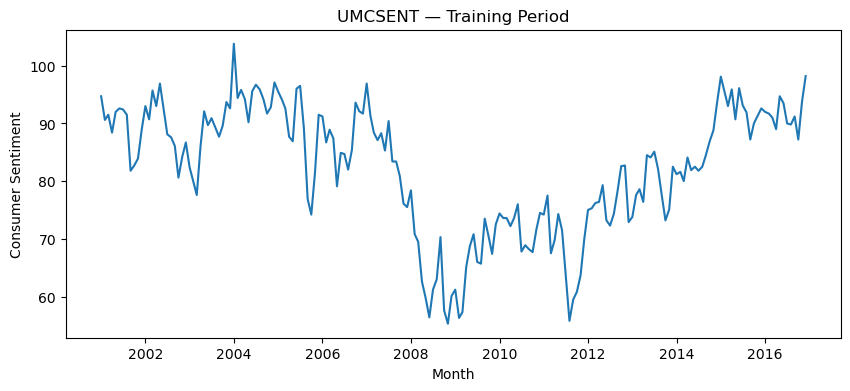

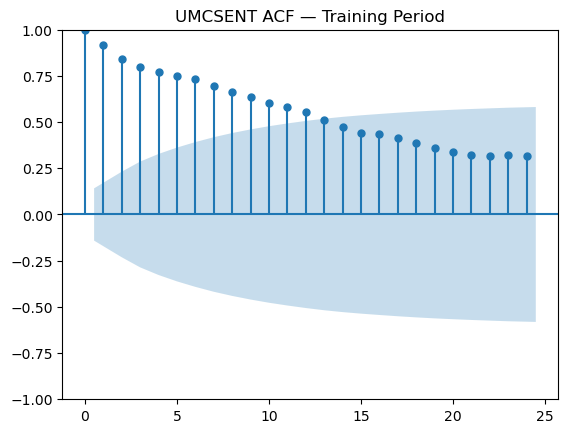

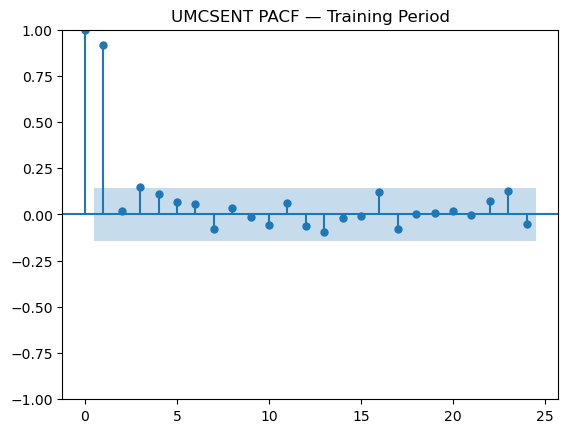

In [46]:
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf,
)

train_umcsent = (
    train
    .set_index("month")["UMCSENT"]
)

# Time-series plot
plt.figure(figsize=(10, 4))
plt.plot(train_umcsent)
plt.title("UMCSENT — Training Period")
plt.xlabel("Month")
plt.ylabel("Consumer Sentiment")
plt.show()

# Autocorrelation
plot_acf(
    train_umcsent,
    lags=24,
)
plt.title("UMCSENT ACF — Training Period")
plt.show()

# Partial autocorrelation
plot_pacf(
    train_umcsent,
    lags=24,
    method="ywm",
)
plt.title("UMCSENT PACF — Training Period")
plt.show()

In [47]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(
    train_umcsent.dropna(),
    autolag="AIC",
)

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Lags used:", adf_result[2])

print("\nCritical values:")
for level, value in adf_result[4].items():
    print(f"{level}: {value}")

ADF statistic: -1.8098521818809647
p-value: 0.3755814455634206
Lags used: 3

Critical values:
1%: -3.465620397124192
5%: -2.8770397560752436
10%: -2.5750324547306476


In [48]:
train_umcsent_diff = (
    train_umcsent
    .diff()
    .dropna()
)

adf_diff = adfuller(
    train_umcsent_diff,
    autolag="AIC",
)

print("Differenced ADF statistic:", adf_diff[0])
print("p-value:", adf_diff[1])
print("Lags used:", adf_diff[2])

print("\nCritical values:")
for level, value in adf_diff[4].items():
    print(f"{level}: {value}")

Differenced ADF statistic: -10.205900038710347
p-value: 5.805755068023127e-18
Lags used: 2

Critical values:
1%: -3.465620397124192
5%: -2.8770397560752436
10%: -2.5750324547306476


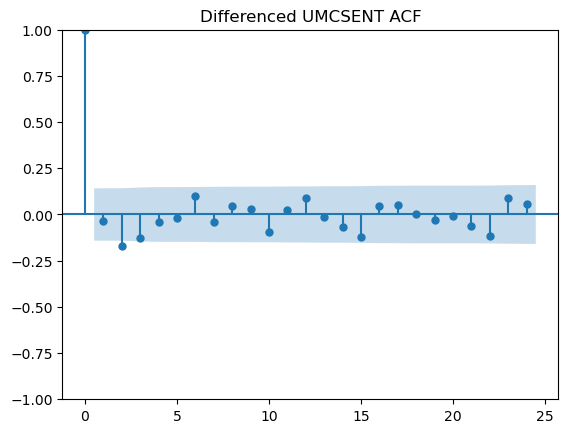

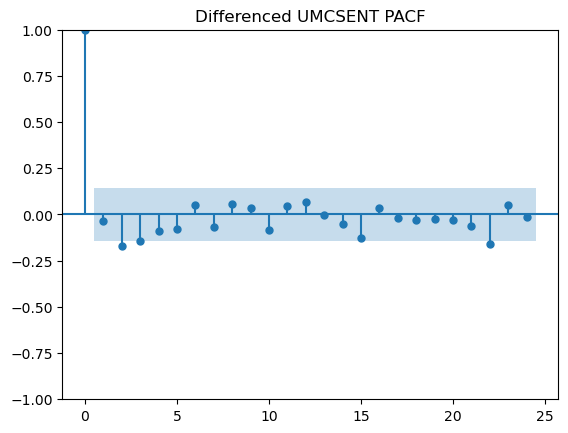

In [49]:
plot_acf(
    train_umcsent_diff,
    lags=24,
)
plt.title("Differenced UMCSENT ACF")
plt.show()

plot_pacf(
    train_umcsent_diff,
    lags=24,
    method="ywm",
)
plt.title("Differenced UMCSENT PACF")
plt.show()

In [50]:
from statsmodels.tsa.arima.model import ARIMA

candidate_orders = [
    (0, 1, 0),
    (1, 1, 0),
    (2, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
]

results = []

for order in candidate_orders:
    model = ARIMA(
        train_umcsent,
        order=order,
    )

    fitted = model.fit()

    results.append(
        {
            "order": order,
            "AIC": fitted.aic,
            "BIC": fitted.bic,
        }
    )

arima_comparison = (
    pd.DataFrame(results)
    .sort_values("AIC")
    .reset_index(drop=True)
)

display(arima_comparison)

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be use

,order,AIC,BIC
0,"(1, 1, 1)",1094.678152,1104.434972
1,"(2, 1, 0)",1096.630743,1106.387563
2,"(0, 1, 0)",1098.578757,1101.831031
3,"(0, 1, 1)",1100.239239,1106.743786
4,"(1, 1, 0)",1100.360331,1106.864878


In [51]:
from statsmodels.stats.diagnostic import acorr_ljungbox

orders_to_check = [
    (0, 1, 0),
    (1, 1, 1),
    (2, 1, 0),
]

for order in orders_to_check:

    fitted = ARIMA(
        train_umcsent,
        order=order,
    ).fit()

    residuals = fitted.resid.dropna()

    lb = acorr_ljungbox(
        residuals,
        lags=[12, 24],
        return_df=True,
    )

    print(f"\nARIMA{order}")
    display(lb)


ARIMA(0, 1, 0)


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,lb_stat,lb_pvalue
12,3.517795,0.990653
24,6.367364,0.999877



ARIMA(1, 1, 1)


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,lb_stat,lb_pvalue
12,2.535530,0.998029
24,5.505305,0.999968



ARIMA(2, 1, 0)


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,lb_stat,lb_pvalue
12,3.551857,0.990235
24,6.696476,0.999805


In [52]:
baseline_test = test[
    ["month", "UMCSENT"]
].copy()

baseline_test["baseline_pred"] = (
    model_data["UMCSENT"]
    .shift(1)
    .loc[test.index]
)

display(
    baseline_test.head()
)

print(
    "Missing predictions:",
    baseline_test["baseline_pred"]
    .isna()
    .sum()
)

,month,UMCSENT,baseline_pred
192,2017-01-01,98.5,98.2
193,2017-02-01,96.3,98.5
194,2017-03-01,96.9,96.3
195,2017-04-01,97.0,96.9
196,2017-05-01,97.1,97.0


Missing predictions: 0


In [53]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)
import numpy as np

baseline_mae = mean_absolute_error(
    baseline_test["UMCSENT"],
    baseline_test["baseline_pred"],
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        baseline_test["UMCSENT"],
        baseline_test["baseline_pred"],
    )
)

print(
    "Baseline MAE:",
    round(baseline_mae, 3),
)

print(
    "Baseline RMSE:",
    round(baseline_rmse, 3),
)

Baseline MAE: 2.927
Baseline RMSE: 4.326


In [54]:
model_data = model_data.copy()

# Training-period scaling only
lyric_mean = train["lyric_sentiment"].mean()
lyric_std = train["lyric_sentiment"].std()

valence_mean = train["valence"].mean()
valence_std = train["valence"].std()

model_data["lyric_z"] = (
    model_data["lyric_sentiment"] - lyric_mean
) / lyric_std

model_data["valence_z"] = (
    model_data["valence"] - valence_mean
) / valence_std

# Core affective music signal
model_data["core_sentiment"] = (
    0.5 * model_data["lyric_z"]
    + 0.5 * model_data["valence_z"]
)

# Music from month t-1 predicting UMCSENT at month t
model_data["core_sentiment_lag1"] = (
    model_data["core_sentiment"].shift(1)
)

print(
    model_data[
        [
            "month",
            "core_sentiment",
            "core_sentiment_lag1",
            "UMCSENT",
        ]
    ]
    .loc[190:195]
)

print(
    "\nMissing lagged predictor:",
    model_data.loc[
        model_data["month"] >= "2017-01-01",
        "core_sentiment_lag1",
    ].isna().sum()
)

         month  core_sentiment  core_sentiment_lag1  UMCSENT
190 2016-11-01        0.014913            -0.052215     93.8
191 2016-12-01        0.066071             0.014913     98.2
192 2017-01-01        0.130522             0.066071     98.5
193 2017-02-01        0.191743             0.130522     96.3
194 2017-03-01       -1.181311             0.191743     96.9
195 2017-04-01       -2.020393            -1.181311     97.0

Missing lagged predictor: 0


In [55]:
import statsmodels.api as sm

model_data["UMCSENT_change"] = (
    model_data["UMCSENT"].diff()
)

aug_train = model_data.loc[
    model_data["month"] < "2017-01-01",
    [
        "UMCSENT_change",
        "core_sentiment_lag1",
    ],
].dropna()

core_model = sm.OLS(
    aug_train["UMCSENT_change"],
    aug_train[["core_sentiment_lag1"]],
).fit()

print(core_model.summary())

                                 OLS Regression Results                                
Dep. Variable:         UMCSENT_change   R-squared (uncentered):                   0.000
Model:                            OLS   Adj. R-squared (uncentered):             -0.005
Method:                 Least Squares   F-statistic:                           0.005795
Date:                Wed, 12 Aug 2026   Prob (F-statistic):                       0.939
Time:                        08:58:33   Log-Likelihood:                         -548.29
No. Observations:                 191   AIC:                                      1099.
Df Residuals:                     190   BIC:                                      1102.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                          coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

In [56]:
beta_core = core_model.params[
    "core_sentiment_lag1"
]

augmented_test = model_data.loc[
    model_data["month"] >= "2017-01-01",
    [
        "month",
        "UMCSENT",
        "core_sentiment_lag1",
    ],
].copy()

# Random-walk prediction
augmented_test["prev_UMCSENT"] = (
    model_data["UMCSENT"]
    .shift(1)
    .loc[augmented_test.index]
)

# Predicted monthly change from music
augmented_test["predicted_change"] = (
    beta_core
    * augmented_test["core_sentiment_lag1"]
)

# Augmented forecast
augmented_test["music_pred"] = (
    augmented_test["prev_UMCSENT"]
    + augmented_test["predicted_change"]
)

music_mae = mean_absolute_error(
    augmented_test["UMCSENT"],
    augmented_test["music_pred"],
)

music_rmse = np.sqrt(
    mean_squared_error(
        augmented_test["UMCSENT"],
        augmented_test["music_pred"],
    )
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Music MAE:", round(music_mae, 3))

print()

print("Baseline RMSE:", round(baseline_rmse, 3))
print("Music RMSE:", round(music_rmse, 3))

display(
    augmented_test[
        [
            "month",
            "UMCSENT",
            "prev_UMCSENT",
            "core_sentiment_lag1",
            "predicted_change",
            "music_pred",
        ]
    ].head()
)

Baseline MAE: 2.927
Music MAE: 2.93

Baseline RMSE: 4.326
Music RMSE: 4.323


,month,UMCSENT,prev_UMCSENT,core_sentiment_lag1,predicted_change,music_pred
192,2017-01-01,98.5,98.2,0.066071,0.002385,98.202385
193,2017-02-01,96.3,98.5,0.130522,0.004712,98.504712
194,2017-03-01,96.9,96.3,0.191743,0.006923,96.306923
195,2017-04-01,97.0,96.9,-1.181311,-0.042649,96.857351
196,2017-05-01,97.1,97.0,-2.020393,-0.072943,96.927057


In [57]:
model_data["lyric_z_lag1"] = (
    model_data["lyric_z"].shift(1)
)

model_data["valence_z_lag1"] = (
    model_data["valence_z"].shift(1)
)

separate_train = model_data.loc[
    model_data["month"] < "2017-01-01",
    [
        "UMCSENT_change",
        "lyric_z_lag1",
        "valence_z_lag1",
    ],
].dropna()

separate_model = sm.OLS(
    separate_train["UMCSENT_change"],
    separate_train[
        [
            "lyric_z_lag1",
            "valence_z_lag1",
        ]
    ],
).fit()

print(separate_model.summary())

                                 OLS Regression Results                                
Dep. Variable:         UMCSENT_change   R-squared (uncentered):                   0.001
Model:                            OLS   Adj. R-squared (uncentered):             -0.010
Method:                 Least Squares   F-statistic:                            0.06651
Date:                Wed, 12 Aug 2026   Prob (F-statistic):                       0.936
Time:                        09:01:17   Log-Likelihood:                         -548.22
No. Observations:                 191   AIC:                                      1100.
Df Residuals:                     189   BIC:                                      1107.
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------

In [58]:
results_table = pd.DataFrame({
    "coefficient": separate_model.params,
    "p_value": separate_model.pvalues,
})

display(results_table)

,coefficient,p_value
lyric_z_lag1,-0.056003,0.859333
valence_z_lag1,0.091920,0.770913


# Appendix — thought process and retired exploration

Everything below is documentation only. These cells are comments so they do not affect the production pipeline above.


In [17]:
# ------------------------------------------------------------------
# A1. Genre-engineering thought process
# ------------------------------------------------------------------
#
# Initial audit:
# - The 550K source's `year` field contained obvious errors, including
#   modern recordings coded as 1900, so Billboard Date was chosen as
#   the authoritative timeline.
# - The broad source `genre` field was useful but not sufficient.
#   In particular, the source Folk category contained systematic
#   reggae/dancehall misclassifications.
#
# Final approach:
# - Use the source broad genre as a fallback.
# - Let only high-confidence exact niche tags vote for overrides.
# - Exact matching was chosen because substring matching created
#   false positives such as:
#       ska -> skate punk
#       dub -> dubstep
#       rap -> trap
# - If niche categories tie, keep the base/source genre.
#
# The audit found 754 unique niche tags, but they did not all require
# explicit manual mapping. Tags were conceptually separated into:
#   vote / inherit / ignore / fallback-to-official.
#
# Current rule configuration:
# - 273 high-confidence voting tags.
# - No duplicated voting tags across final categories.
# - No conflicts between vote / inherit / ignore sets.
#
# Religious/context tags were kept separate from primary genre.
# Example:
#   christian hip hop can vote Hip-Hop AND religious_music = 1.
# `catholic music` was later added to RELIGIOUS_TAGS after audit.
#
# The old detailed tag-audit displays and exploratory Folk tables were
# removed from the production notebook because they were useful for
# developing the rule set, not necessary to rerun every time.


In [18]:
# ------------------------------------------------------------------
# A2. Duplicate Spotify-row thought process
# ------------------------------------------------------------------
#
# The 550K table frequently repeats the same title + artist across
# albums, compilations, reissues, and duplicate catalog entries.
#
# Two manual test cases were used to design the canonical-row rule:
#
# Drive — The Cars
# - 70 candidate rows.
# - Dominant rounded audio profile appeared 37 times.
# - Within that profile, the highest-popularity row was the
#   Heartbeat City recording:
#   Spotify ID 3wfujdbamR3Z46F4xav7LM.
#
# Last Last — Burna Boy
# - 22 candidate rows.
# - Dominant rounded audio profile appeared 21 times.
# - Within that profile, the highest-popularity row was the
#   Love, Damini recording:
#   Spotify ID 5YbPxJwPfrj7uswNwoF1pJ.
#
# This led to the production precedence:
#   most common rounded audio signature
#   -> highest popularity within that signature
#   -> Spotify ID as stable tie-breaker.
#
# The rounded signature uses danceability, energy, valence, tempo,
# and duration only for duplicate resolution. The original feature
# values remain untouched for analysis.


In [19]:
# ------------------------------------------------------------------
# A3. Matching thought process: Passes 1 and 2
# ------------------------------------------------------------------
#
# Pass 1:
# - Strict normalized title + strict normalized artist.
# - Last observed result: 10,466 matches.
#
# Early title-only diagnostics were explicitly rejected.
# A title-only merge expanded 22,126 unmatched Billboard songs into
# 122,498 candidate rows because titles such as Stay / Monster / Drive
# belong to many unrelated artists. That number was NOT match coverage.
#
# A safer diagnostic found:
# - 11,868 unmatched Billboard songs had a title that existed somewhere
#   in the canonical 550K table.
# - 10,258 had no exact normalized title in the table.
#
# Among exact-title misses, Billboard collaboration formatting was a
# major pattern:
#   Drake Featuring Jhene Aiko  vs  Spotify primary artist Drake.
#
# A first diagnostic restricted to titles with one Spotify candidate:
# - 3,112 such Billboard songs.
# - Removing an explicit Billboard "Featuring ..." suffix recovered 328.
#
# After spot checking those 328, the same conservative rule was applied
# to ALL unmatched Billboard songs rather than only the single-title
# subset.
#
# Production Pass 2 result:
# - 798 additional matches.
#
# A later diagnostic showed all 1,131 still-unmatched Featuring-credit
# rows had no exact same-title Spotify candidate under the stripped lead
# artist. This supported freezing Pass 2 rather than repeatedly relaxing it.


In [20]:
# ------------------------------------------------------------------
# A4. Matching thought process: title feature credits / Pass 3
# ------------------------------------------------------------------
#
# Large unresolved artists such as Taylor Swift initially looked like
# an alias problem. Inspection showed that exact titles often existed
# only under covers/other artists, so "title exists" could not imply a
# valid match.
#
# Taylor-specific version inspection found only a handful of startswith
# candidates (for example remix / feat. variants), so generic version
# stripping was NOT adopted.
#
# First attempt:
# - Strip everything after `feat` from the normalized Spotify title.
# - Produced 1,097 candidates.
# - Rejected because it incorrectly collapsed examples such as:
#     Roses (feat. ROZES) - Loosid Remix -> Roses
#     Booty (...) - Remix -> Booty
#     Suit & Tie (...) - Radio Edit -> Suit & Tie
#   This is especially dangerous because the project models AUDIO
#   features; a remix can have meaningfully different valence/energy.
#
# Safer rule:
# - Remove only the feature-credit phrase from the ORIGINAL Spotify name.
# - Preserve any remaining Remix / Radio Edit / other version text.
# - Result: 815 candidates.
#
# Collaborator validation:
# - Require explicit Billboard Featuring credit.
# - Require at least one Spotify secondary artist to overlap the
#   Billboard credit.
#
# Crosstab from the audit:
#   Billboard no Featuring + no overlap: 55
#   Billboard Featuring + no overlap:    32
#   Billboard Featuring + overlap:      728 candidate rows
#
# Those 728 candidate rows represented 714 Billboard songs:
# - 700 songs had exactly one surviving Spotify candidate.
# - 14 songs had two surviving candidates each.
#
# The 700 unique cases became the automatic Pass-3 matches.


In [21]:
# ------------------------------------------------------------------
# A5. Manual audit of the 14 ambiguous Pass-3 songs
# ------------------------------------------------------------------
#
# Twelve were resolvable from collaborator credits and/or duplicate
# recording metadata. Their audited Spotify IDs are preserved in
# PASS3_MANUAL_IDS in the production matcher.
#
# Examples:
# - Bang My Head:
#     Billboard = Sia & Fetty Wap
#     chose the Spotify row containing both.
# - Essence:
#     Billboard = Justin Bieber & Tems
#     chose the Spotify row containing both.
# - Ima Boss:
#     Billboard's collaborator cast identifies the remix, so in this
#     case the remix IS the charted version rather than an invalid
#     substitute.
# - Monsters:
#     chose Demi Lovato + blackbear rather than blackbear-only.
# - Show Me Love:
#     chose Miguel-only rather than 21 Savage + Miguel.
# - What's Luv?:
#     chose Ashanti-only rather than Ja Rule + Ashanti.
#
# Near-duplicate metadata/audio cases reviewed manually included:
# - Let's Go
# - Neck & Wrist
# - Off The Books
# - Shut Up
# - Writing On The Wall
#
# Two cases were deliberately left unresolved because Billboard itself
# used "Or" and the Spotify rows represented separate versions:
# - Into You — Fabolous Featuring Tamia Or Ashanti
# - Thinking 'Bout You — Dustin Lynch Featuring
#   Lauren Alaina Or MacKenzie Porter
#
# Final last-observed match counts:
# - exact_title_artist:                                  10,466
# - exact_title_lead_artist_after_featuring:                798
# - feature-title strip + collaborator overlap:              700
# - manual ambiguous feature-credit review:                   12
# - total matched unique Billboard song-artist pairs:      11,976
# - unique-song coverage:                                  36.7%


In [22]:
# ------------------------------------------------------------------
# A6. Coverage / analysis-window thought process
# ------------------------------------------------------------------
#
# Raw weekly-row coverage was inspected by year after matching.
# It was reasonably strong in many 2000s/2010s years but fell sharply
# in the 2020s, becoming extremely sparse by 2024-2026.
#
# An earlier working idea proposed 1999-2018 as an analysis window
# based on the UNWEIGHTED weekly match rate. That cutoff was retired.
#
# Why it was retired:
# - The final music signal is popularity-weighted.
# - Missing the #1 song matters much more than missing #100.
# - Therefore the usable period should be judged using rank-weighted
#   MONTHLY coverage, not only raw matched-row percentages.
#
# Current production diagnostics now compute:
# - raw weekly coverage by year,
# - rank-weighted coverage by year,
# - rank-weighted coverage by month.
#
# No final date cutoff should be frozen until those monthly weighted
# coverage results are inspected.
#
# Important boundary:
# If recent years remain extremely sparse after rank weighting, do not
# force weak/fuzzy matches simply to make the project more current.
# Report the coverage limitation or revise the source strategy instead.
